In [4]:
import pandas as pd
import numpy as np

In [5]:
df = pd.read_csv("../data/creditcard.csv")

In [6]:
df_clean = df.copy()

In [7]:
print("Shape before removing duplicates:", df_clean.shape)

print("Number of duplicate rows:", df_clean.duplicated().sum())

Shape before removing duplicates: (284807, 31)
Number of duplicate rows: 1081


In [8]:
df_dedup = df_clean.drop_duplicates().copy()

print("Original working copy:", df_clean.shape)
print("After removing duplicates:", df_dedup.shape)


Original working copy: (284807, 31)
After removing duplicates: (283726, 31)


In [9]:
print("Class distribution before removing duplicates:")
print(df_clean["Class"].value_counts())

print("\nClass distribution after removing duplicates:")
print(df_dedup["Class"].value_counts())

Class distribution before removing duplicates:
Class
0    284315
1       492
Name: count, dtype: int64

Class distribution after removing duplicates:
Class
0    283253
1       473
Name: count, dtype: int64


In [10]:
print("Fraud percentage before removing duplicates:")
print(df_clean["Class"].value_counts(normalize=True) * 100)

print("\nFraud percentage after removing duplicates:")
print(df_dedup["Class"].value_counts(normalize=True) * 100)

Fraud percentage before removing duplicates:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

Fraud percentage after removing duplicates:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


In [11]:
df_model = df_dedup.copy()

print(df_model.shape)

(283726, 31)


In [12]:
X = df_model.drop("Class", axis=1)
y = df_model["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (283726, 30)
y shape: (283726,)


In [13]:
print(X.head())
print(y.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V20       V21       V22       V23       V24  \
0  0.098698  0.363787  ...  0.251412 -0.018307  0.277838 -0.110474  0.066928   
1  0.085102 -0.255425  ... -0.069083 -0.225775 -0.638672  0.101288 -0.339846   
2  0.247676 -1.514654  ...  0.524980  0.247998  0.771679  0.909412 -0.689281   
3  0.377436 -1.387024  ... -0.208038 -0.108300  0.005274 -0.190321 -1.175575   
4 -0.270533  0.817739  ...  0.408542 -0.009431  0.798278 -0.137458  0.141267   

        V25       V26       V27 

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (226980, 30)
X_test: (56746, 30)
y_train: (226980,)
y_test: (56746,)


In [15]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTraining class percentages:")
print(y_train.value_counts(normalize=True) * 100)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Training class percentages:
Class
0    99.833466
1     0.166534
Name: proportion, dtype: float64


In [16]:
print("Test class distribution:")
print(y_test.value_counts())

print("\nTest class percentages:")
print(y_test.value_counts(normalize=True) * 100)

Test class distribution:
Class
0    56651
1       95
Name: count, dtype: int64

Test class percentages:
Class
0    99.832587
1     0.167413
Name: proportion, dtype: float64


In [17]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

print("Predicted classes:")
print(pd.Series(dummy_predictions).value_counts())

Predicted classes:
0    56746
Name: count, dtype: int64


In [18]:
print("Actual fraud cases in test set:", y_test.sum())
print("Fraud cases predicted by dummy model:", dummy_predictions.sum())

Actual fraud cases in test set: 95
Fraud cases predicted by dummy model: 0


In [19]:
from sklearn.linear_model import LogisticRegression


In [20]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [21]:
logistic_model.fit(X_train, y_train)

c:\Projects\credit-card-fraud-detection\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [22]:
y_pred = logistic_model.predict(X_test)

print("Predicted classes:")
print(pd.Series(y_pred).value_counts())


Predicted classes:
0    56683
1       63
Name: count, dtype: int64


In [23]:
from sklearn.preprocessing import StandardScaler

In [24]:
print("X_train exists:", "X_train" in globals())
print("y_train exists:", "y_train" in globals())
print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())

X_train exists: True
y_train exists: True
X_test exists: True
y_test exists: True


In [25]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (226980, 30)
X_test: (56746, 30)
y_train: (226980,)
y_test: (56746,)


In [26]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [27]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled train shape: (226980, 30)
Scaled test shape: (56746, 30)


In [28]:
from sklearn.linear_model import LogisticRegression

logistic_model_scaled = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = logistic_model_scaled.predict(X_test_scaled)

In [29]:
print(pd.Series(y_pred_scaled).value_counts())

0    56681
1       65
Name: count, dtype: int64


[[56641    10]
 [   40    55]]


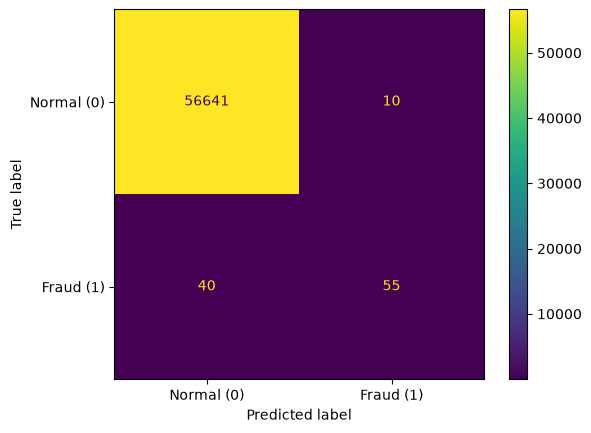

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_scaled, labels=[0, 1])

print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal (0)", "Fraud (1)"]
)

display.plot()
plt.show()

In [31]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_scaled,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56651
       Fraud       0.85      0.58      0.69        95

    accuracy                           1.00     56746
   macro avg       0.92      0.79      0.84     56746
weighted avg       1.00      1.00      1.00     56746



In [32]:
logistic_model_balanced = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

logistic_model_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = logistic_model_balanced.predict(X_test_scaled)

[[55262  1389]
 [   12    83]]


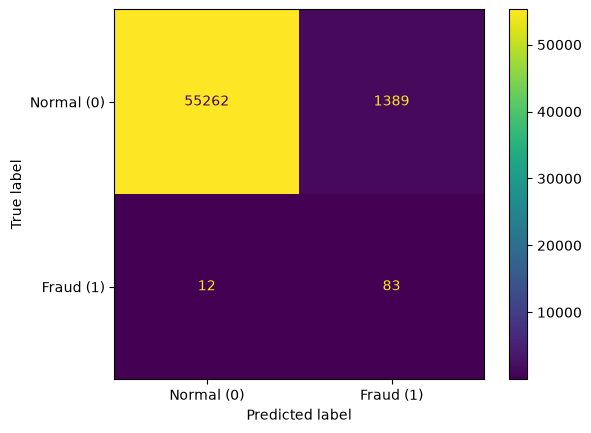

In [33]:
cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=[0, 1]
)

print(cm_balanced)

ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["Normal (0)", "Fraud (1)"]
).plot()

plt.show()

In [34]:
print(classification_report(
    y_test,
    y_pred_balanced,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



In [35]:
from imblearn.over_sampling import SMOTE

print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64


In [36]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("After SMOTE:")
print(y_train_smote.value_counts())

print("New training shape:", X_train_smote.shape)

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64
New training shape: (453204, 30)


In [37]:
logistic_model_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = logistic_model_smote.predict(X_test_scaled)

[[55169  1482]
 [   12    83]]


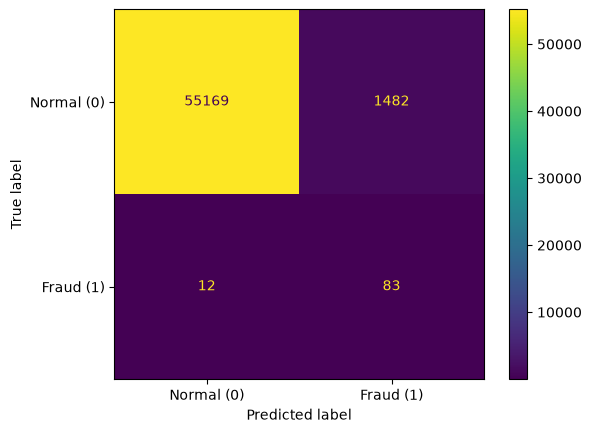

In [38]:
cm_smote = confusion_matrix(
    y_test,
    y_pred_smote,
    labels=[0, 1]
)

print(cm_smote)

ConfusionMatrixDisplay(
    confusion_matrix=cm_smote,
    display_labels=["Normal (0)", "Fraud (1)"]
).plot()

plt.show()

In [39]:
print(classification_report(
    y_test,
    y_pred_smote,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

              precision    recall  f1-score   support

      Normal       1.00      0.97      0.99     56651
       Fraud       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746



In [40]:
from sklearn.model_selection import train_test_split

X_train_inner, X_val, y_train_inner, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Inner training:", X_train_inner.shape)
print("Validation:", X_val.shape)

print("\nInner training classes:")
print(y_train_inner.value_counts())

print("\nValidation classes:")
print(y_val.value_counts())

Inner training: (181584, 30)
Validation: (45396, 30)

Inner training classes:
Class
0    181282
1       302
Name: count, dtype: int64

Validation classes:
Class
0    45320
1       76
Name: count, dtype: int64


In [41]:
from sklearn.preprocessing import StandardScaler

scaler_val = StandardScaler()

X_train_inner_scaled = scaler_val.fit_transform(X_train_inner)
X_val_scaled = scaler_val.transform(X_val)

print("Scaled inner train:", X_train_inner_scaled.shape)
print("Scaled validation:", X_val_scaled.shape)

Scaled inner train: (181584, 30)
Scaled validation: (45396, 30)


In [42]:
from imblearn.over_sampling import SMOTE

smote_val = SMOTE(random_state=42)

X_train_inner_smote, y_train_inner_smote = smote_val.fit_resample(
    X_train_inner_scaled,
    y_train_inner
)

print(y_train_inner_smote.value_counts())
print("Resampled shape:", X_train_inner_smote.shape)

Class
0    181282
1    181282
Name: count, dtype: int64
Resampled shape: (362564, 30)


In [43]:
logistic_model_val = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model_val.fit(
    X_train_inner_smote,
    y_train_inner_smote
)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [44]:
y_val_proba = logistic_model_val.predict_proba(X_val_scaled)[:, 1]

print(y_val_proba[:10])

[0.00337192 0.02333503 0.01113681 0.01884402 0.00685302 0.00564592
 0.0029301  0.01266173 0.00144482 0.10512476]


In [45]:
y_val_pred_05 = (y_val_proba >= 0.5).astype(int)

print(pd.Series(y_val_pred_05).value_counts())

0    44038
1     1358
Name: count, dtype: int64


In [46]:
cm_val_05 = confusion_matrix(
    y_val,
    y_val_pred_05,
    labels=[0, 1]
)

print(cm_val_05)

print(classification_report(
    y_val,
    y_val_pred_05,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

[[44031  1289]
 [    7    69]]
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.99     45320
       Fraud       0.05      0.91      0.10        76

    accuracy                           0.97     45396
   macro avg       0.53      0.94      0.54     45396
weighted avg       1.00      0.97      0.98     45396



In [47]:
y_val_pred_02 = (y_val_proba >= 0.2).astype(int)

print(confusion_matrix(
    y_val,
    y_val_pred_02,
    labels=[0, 1]
))

print(classification_report(
    y_val,
    y_val_pred_02,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

[[41173  4147]
 [    7    69]]
              precision    recall  f1-score   support

      Normal       1.00      0.91      0.95     45320
       Fraud       0.02      0.91      0.03        76

    accuracy                           0.91     45396
   macro avg       0.51      0.91      0.49     45396
weighted avg       1.00      0.91      0.95     45396



In [48]:
from sklearn.metrics import confusion_matrix

thresholds = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred_threshold,
        labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall
    })

threshold_results = pd.DataFrame(results)

threshold_results

,Threshold,TP,FP,FN,Precision,Recall
0,0.01,76,30309,0,0.002501,1.000000
1,0.05,73,12746,3,0.005695,0.960526
2,0.10,73,7713,3,0.009376,0.960526
3,0.20,69,4147,7,0.016366,0.907895
4,0.30,69,2660,7,0.025284,0.907895
5,0.50,69,1289,7,0.050810,0.907895
6,0.70,67,649,9,0.093575,0.881579
7,0.90,66,275,10,0.193548,0.868421


In [49]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

# 1. Apply SMOTE only to the inner training data
smote_rf = SMOTE(random_state=42)

X_train_inner_smote_rf, y_train_inner_smote_rf = smote_rf.fit_resample(
    X_train_inner,
    y_train_inner
)

print("Training data shape after SMOTE:", X_train_inner_smote_rf.shape)
print("\nClass counts after SMOTE:")
print(y_train_inner_smote_rf.value_counts())

# 2. Train the Random Forest model
rf_model_val = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model_val.fit(
    X_train_inner_smote_rf,
    y_train_inner_smote_rf
)

# 3. Predict on the untouched validation data
y_val_pred_rf = rf_model_val.predict(X_val)

# 4. Evaluate
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_rf,
    labels=[0, 1],
    target_names=["Normal", "Fraud"],
    zero_division=0
))

Training data shape after SMOTE: (362564, 30)

Class counts after SMOTE:
Class
0    181282
1    181282
Name: count, dtype: int64

Confusion Matrix:
[[45315     5]
 [   11    65]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     45320
       Fraud       0.93      0.86      0.89        76

    accuracy                           1.00     45396
   macro avg       0.96      0.93      0.95     45396
weighted avg       1.00      1.00      1.00     45396



In [50]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_comparison = pd.DataFrame([
    {
        "Model": "SMOTE Logistic Regression",
        "Precision": precision_score(y_val, (y_val_proba >= 0.5).astype(int)),
        "Recall": recall_score(y_val, (y_val_proba >= 0.5).astype(int)),
        "F1-score": f1_score(y_val, (y_val_proba >= 0.5).astype(int))
    },
    {
        "Model": "SMOTE Random Forest",
        "Precision": precision_score(y_val, y_val_pred_rf),
        "Recall": recall_score(y_val, y_val_pred_rf),
        "F1-score": f1_score(y_val, y_val_pred_rf)
    }
])

model_comparison

,Model,Precision,Recall,F1-score
0,SMOTE Logistic Regression,0.050810,0.907895,0.096234
1,SMOTE Random Forest,0.928571,0.855263,0.890411


In [51]:
feature_importance = pd.DataFrame({
    "Feature": X_train_inner.columns,
    "Importance": rf_model_val.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
14,V14,0.226330
10,V10,0.125052
12,V12,0.104034
4,V4,0.101499
17,V17,0.090800
3,V3,0.082346
11,V11,0.049280
16,V16,0.040855
2,V2,0.038966
9,V9,0.026816


In [52]:
y_val_proba_rf = rf_model_val.predict_proba(X_val)[:, 1]

thresholds_rf = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results_rf = []

for threshold in thresholds_rf:
    y_pred_threshold_rf = (y_val_proba_rf >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred_threshold_rf,
        labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    results_rf.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall
    })

threshold_results_rf = pd.DataFrame(results_rf)

threshold_results_rf

,Threshold,TP,FP,FN,Precision,Recall
0,0.1,67,138,9,0.326829,0.881579
1,0.2,66,38,10,0.634615,0.868421
2,0.3,66,15,10,0.814815,0.868421
3,0.4,66,7,10,0.904110,0.868421
4,0.5,65,5,11,0.928571,0.855263
5,0.6,65,5,11,0.928571,0.855263
6,0.7,63,5,13,0.926471,0.828947
7,0.8,59,4,17,0.936508,0.776316
8,0.9,55,1,21,0.982143,0.723684


In [53]:
import xgboost

print(xgboost.__version__)

3.4.1


In [54]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [55]:
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, classification_report

xgb_model_val = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

xgb_model_val.fit(
    X_train_inner_smote_rf,
    y_train_inner_smote_rf
)

y_val_pred_xgb = xgb_model_val.predict(X_val)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_xgb,
    labels=[0, 1],
    target_names=["Normal", "Fraud"],
    zero_division=0
))

Confusion Matrix:
[[45259    61]
 [   10    66]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     45320
       Fraud       0.52      0.87      0.65        76

    accuracy                           1.00     45396
   macro avg       0.76      0.93      0.82     45396
weighted avg       1.00      1.00      1.00     45396



In [56]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_comparison = pd.DataFrame([
    {
        "Model": "SMOTE Logistic Regression",
        "Precision": precision_score(
            y_val, (y_val_proba >= 0.5).astype(int)
        ),
        "Recall": recall_score(
            y_val, (y_val_proba >= 0.5).astype(int)
        ),
        "F1-score": f1_score(
            y_val, (y_val_proba >= 0.5).astype(int)
        )
    },
    {
        "Model": "SMOTE Random Forest",
        "Precision": precision_score(y_val, y_val_pred_rf),
        "Recall": recall_score(y_val, y_val_pred_rf),
        "F1-score": f1_score(y_val, y_val_pred_rf)
    },
    {
        "Model": "SMOTE XGBoost",
        "Precision": precision_score(y_val, y_val_pred_xgb),
        "Recall": recall_score(y_val, y_val_pred_xgb),
        "F1-score": f1_score(y_val, y_val_pred_xgb)
    }
])

model_comparison

,Model,Precision,Recall,F1-score
0,SMOTE Logistic Regression,0.050810,0.907895,0.096234
1,SMOTE Random Forest,0.928571,0.855263,0.890411
2,SMOTE XGBoost,0.519685,0.868421,0.650246


In [57]:
# Predicted probability of fraud (Class 1) for each model

model_probabilities = {
    "SMOTE Logistic Regression": y_val_proba,
    "SMOTE Random Forest": y_val_proba_rf,
    "SMOTE XGBoost": xgb_model_val.predict_proba(X_val)[:, 1]
}

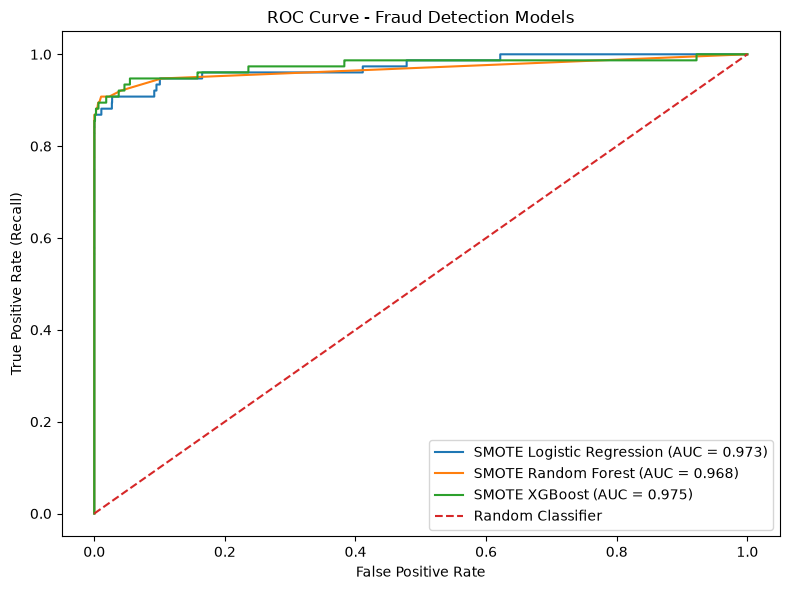

In [58]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

for model_name, probabilities in model_probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_val, probabilities)
    auc_score = roc_auc_score(y_val, probabilities)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_score:.3f})"
    )

# Random guessing reference line
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Fraud Detection Models")
plt.legend()
plt.tight_layout()
plt.show()

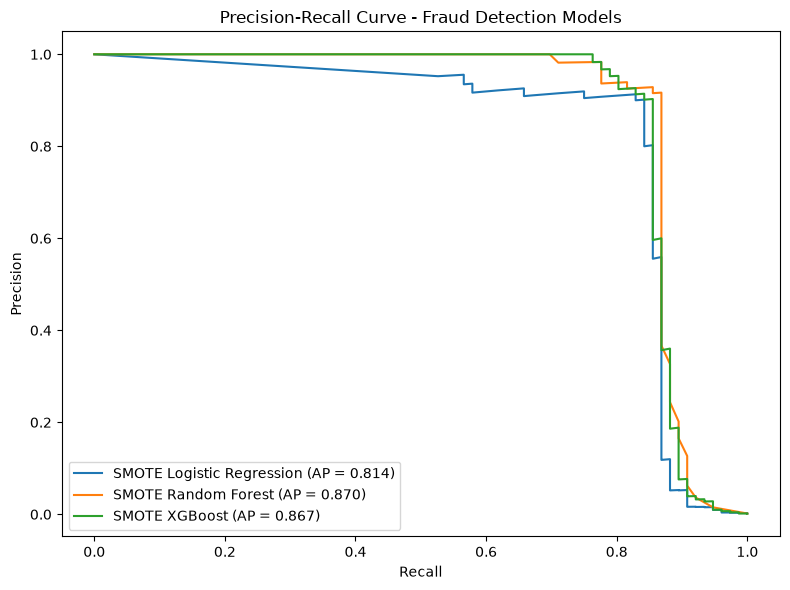

In [59]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for model_name, probabilities in model_probabilities.items():
    precision, recall, thresholds = precision_recall_curve(
        y_val,
        probabilities
    )

    ap_score = average_precision_score(y_val, probabilities)

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap_score:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Fraud Detection Models")
plt.legend()
plt.tight_layout()
plt.show()

In [60]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# Apply SMOTE to the full training data
smote_final = SMOTE(random_state=42)

X_train_smote_final, y_train_smote_final = smote_final.fit_resample(
    X_train,
    y_train
)

print("Training shape after SMOTE:", X_train_smote_final.shape)
print("\nClass counts:")
print(y_train_smote_final.value_counts())

# Train the final Random Forest model
rf_model_final = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model_final.fit(
    X_train_smote_final,
    y_train_smote_final
)

Training shape after SMOTE: (453204, 30)

Class counts:
Class
0    226602
1    226602
Name: count, dtype: int64


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [61]:
from sklearn.metrics import confusion_matrix, classification_report

# Predict on the test set
y_test_pred_rf = rf_model_final.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_rf,
    labels=[0, 1],
    target_names=["Normal", "Fraud"],
    zero_division=0
))

Confusion Matrix:
[[56642     9]
 [   22    73]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56651
       Fraud       0.89      0.77      0.82        95

    accuracy                           1.00     56746
   macro avg       0.94      0.88      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [62]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_test_proba_rf = rf_model_final.predict_proba(X_test)[:, 1]

test_roc_auc = roc_auc_score(y_test, y_test_proba_rf)
test_ap = average_precision_score(y_test, y_test_proba_rf)

print("Test ROC AUC:", round(test_roc_auc, 4))
print("Test Average Precision:", round(test_ap, 4))

Test ROC AUC: 0.9609
Test Average Precision: 0.8043


In [63]:
%pip install streamlit

   ---------------------------------------- 0.0/10.4 MB ? eta -:--:--
   -------------------- ------------------- 5.2/10.4 MB 29.3 MB/s eta 0:00:01
   ---------------------------------------  10.2/10.4 MB 25.7 MB/s eta 0:00:01
   ---------------------------------------- 10.4/10.4 MB 21.8 MB/s  0:00:00
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 7.5 MB/s  0:00:00
   ---------------------------------------- 0.0/28.5 MB ? eta -:--:--
   ------- -------------------------------- 5.2/28.5 MB 26.1 MB/s eta 0:00:01
   --------- ------------------------------ 7.1/28.5 MB 16.7 MB/s eta 0:00:02
   ------------ --------------------------- 8.9/28.5 MB 14.0 MB/s eta 0:00:02
   -------------- ------------------------- 10.5/28.5 MB 12.0 MB/s eta 0:00:02
   --------------- ------------------------ 11.3/28.5 MB 10.7 MB/s eta 0:00:02
   ---------------- ----------------------- 11.8/28.5 MB 9.4 MB/s eta 0:00:02
   ------